In this notebook,I look at the Krause21 and vandenBerg_table2 datasets to see how globular cluster age changes with metallicity.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
krause = pd.read_csv("Krause21.csv")
vanden = pd.read_csv("vandenBerg_table2.csv")

print(krause.columns)
print(vanden.columns)

Index(['Class', 'Object', 'AltName', 'Mstar', 'rh', 'C5', 'Age', 'FeH'], dtype='object')
Index(['#NGC', 'Name', 'FeH', 'Age', 'Age_err', 'Method', 'Figs', 'Range',
       'HBtype', 'R_G', 'M_V', 'v_e0', 'log_sigma_0'],
      dtype='object')


In [3]:
krause.head()

,Class,Object,AltName,Mstar,rh,C5,Age,FeH
0,GC,NGC104,47Tuc,6.46,7.10,0.92,12.80,-0.76
1,GC,NGC288,Melotte3,0.46,9.80,0.05,12.20,-1.32
2,GC,NGC362,Dunlop62,2.50,3.50,0.72,10.00,-1.26
3,GC,NGC1261,Caldwell87,3.41,5.50,0.62,10.24,-1.08
4,GC,NGC1851,Dunlop508,5.51,3.05,1.81,7.64,-1.13


In [4]:
vanden.head()
print(krause.shape)
print(vanden.shape)
print(krause.isnull().sum())
print(vanden.isnull().sum())

(61, 8)
(55, 13)
Class      0
Object     0
AltName    0
Mstar      0
rh         0
C5         0
Age        0
FeH        0
dtype: int64
#NGC            0
Name            0
FeH             0
Age             0
Age_err         0
Method          0
Figs            0
Range          22
HBtype          0
R_G             0
M_V             0
v_e0            0
log_sigma_0     0
dtype: int64


In [5]:
print("Krause21 summary:")  
print(krause[['Age', 'FeH']].describe())  

print("\nVandenBerg summary:")
print(vanden[['Age', 'FeH']].describe())

Krause21 summary:
             Age        FeH
count  61.000000  61.000000
mean   12.202951  -1.348361
std     1.392268   0.505326
min     7.400000  -2.330000
25%    11.600000  -1.580000
50%    12.500000  -1.340000
75%    13.100000  -0.990000
max    14.600000  -0.120000

VandenBerg summary:
             Age        FeH
count  55.000000  55.000000
mean   11.900000  -1.455818
std     0.811663   0.562878
min     9.000000  -2.350000
25%    11.375000  -1.820000
50%    12.000000  -1.510000
75%    12.500000  -1.140000
max    13.000000  -0.290000


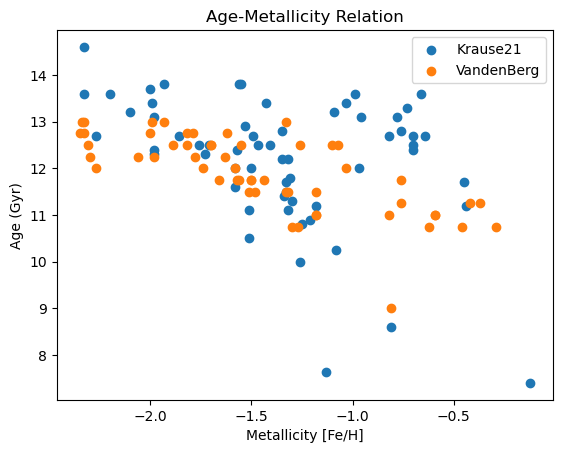

In [6]:
import matplotlib.pyplot as plt

plt.scatter(krause['FeH'], krause['Age'], label='Krause21')
plt.scatter(vanden['FeH'], vanden['Age'], label='VandenBerg')

plt.xlabel('Metallicity [Fe/H]')
plt.ylabel('Age (Gyr)')
plt.title('Age-Metallicity Relation')
plt.legend()
plt.show()

In [7]:
print("Krause21 correlation:")
print(krause[['Age', 'FeH']].corr())

print("\nVandenBerg correlation:")
print(vanden[['Age', 'FeH']].corr())

Krause21 correlation:
          Age       FeH
Age  1.000000 -0.398165
FeH -0.398165  1.000000

VandenBerg correlation:
          Age       FeH
Age  1.000000 -0.717933
FeH -0.717933  1.000000


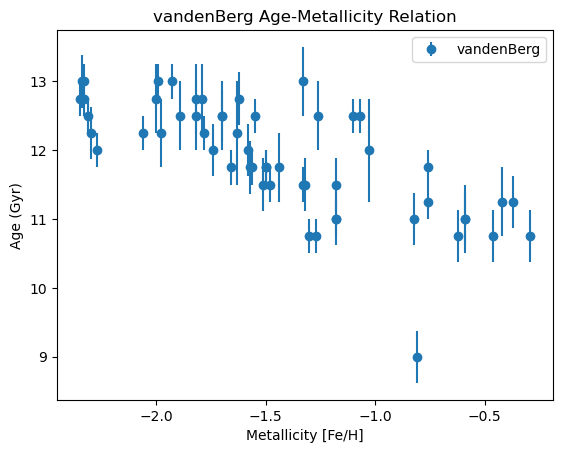

In [8]:
plt.errorbar(
    vanden['FeH'], 
    vanden['Age'],
    yerr=vanden['Age_err'],
    fmt='o',
    label='vandenBerg'
)
plt.xlabel('Metallicity [Fe/H]')
plt.ylabel('Age (Gyr)')
plt.title('vandenBerg Age-Metallicity Relation')
plt.legend()
plt.show()

The vandenBerg data seems to show that clusters with higher metallicity are generally younger.There is some variation in the age values, and the error bars show that the measurements are not exact.The correlation result also supports this trend,since the age and metallicity have a fairly strong negative correlation.

In [9]:
krause['fit'] = np.polyval(np.polyfit(krause['FeH'], krause['Age'], 1), krause['FeH'])
vanden['fit'] = np.polyval(np.polyfit(vanden['FeH'], vanden['Age'], 1), vanden['FeH'])

krause['residuals'] = krause['Age'] - krause['fit']
vanden['residuals'] = vanden['Age'] - vanden['fit']

krause['candidate'] = abs(krause['residuals']) > 2 * krause['residuals'].std()
vanden['candidate'] = abs(vanden['residuals']) > 2 * vanden['residuals'].std()

In [10]:
print("Krause21 candidates:")
display(krause[krause['candidate']][['Object', 'Age', 'FeH', 'residuals']])

print("VandenBerg candidates:")
display(vanden[vanden['candidate']][['Name', 'Age', 'FeH', 'Age_err' ,'residuals']])

Krause21 candidates:


,Object,Age,FeH,residuals
4,NGC1851,7.64,-1.13,-4.323405
59,Terzan7,7.40,-0.12,-3.455415
60,Palomar12,8.60,-0.81,-3.012359


VandenBerg candidates:


,Name,Age,FeH,Age_err,residuals
23,M12,13.0,-1.33,0.50,1.230253
53,Pal12,9.0,-0.81,0.38,-2.231418


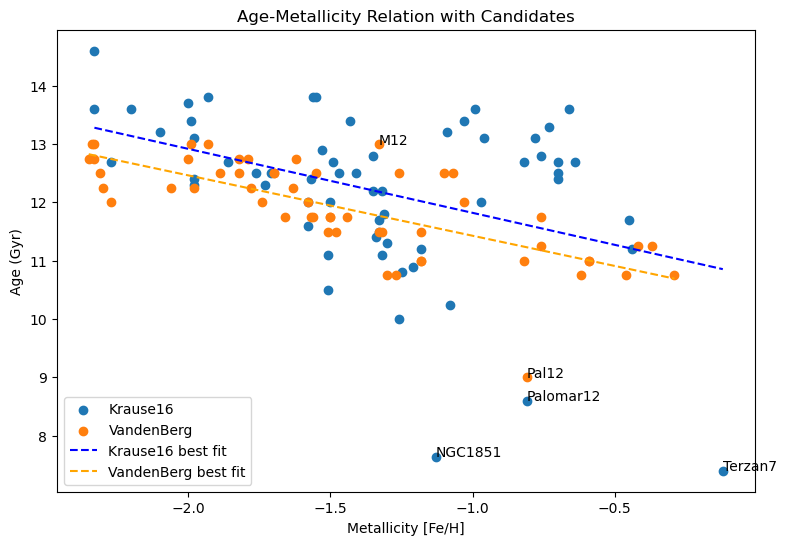

In [11]:
plt.figure(figsize=(9, 6))

plt.scatter(krause['FeH'], krause['Age'], label='Krause16')
plt.scatter(vanden['FeH'], vanden['Age'], label='VandenBerg')

plt.plot(
    krause['FeH'].sort_values(),
    krause.sort_values('FeH')['fit'],
    color='blue',
    linestyle='--',
    label='Krause16 best fit'
)

plt.plot(
    vanden['FeH'].sort_values(),
    vanden.sort_values('FeH')['fit'],
    color='orange',
    linestyle='--',
    label='VandenBerg best fit'
)

for _, row in krause[krause['candidate']].iterrows():
    plt.annotate(row['Object'], (row['FeH'], row['Age']))

for _, row in vanden[vanden['candidate']].iterrows():
    plt.annotate(row['Name'], (row['FeH'], row['Age']))

plt.xlabel('Metallicity [Fe/H]')
plt.ylabel('Age (Gyr)')
plt.title('Age-Metallicity Relation with Candidates')
plt.legend()
plt.savefig("age_metallicity_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

I fitted a simple age-metallicity trend and used the residuals to find unusual clusters.I also checked the age uncertainties in the vandenBerg data.These are only possible candidates for further study,not confirmed accreted clusters.